### Paso 1: Configuración del Entorno y Selección del Subconjunto
Cargamos el corpus Tobacco3482 y seleccionamos un subconjunto balanceado y aleatorio (semilla 42) de 300 documentos distribuidos equitativamente en 4 clases (75 imágenes para Memo, Letter, Form y Report). Esta selección balanceada evita sesgos en el entrenamiento de los modelos de clasificación.

In [ ]:
import kagglehub

# Descarga automáticamente el conjunto de datos Tobacco3482
path = kagglehub.dataset_download("patrickaudriaz/tobacco3482jpg")

print("El dataset se descargó en:", path)

Using Colab cache for faster access to the 'tobacco3482jpg' dataset.
El dataset se descargó en: /kaggle/input/tobacco3482jpg


In [ ]:
import os

# Muestra las carpetas/categorías encontradas
print("Carpetas de datos:", os.listdir(path))

Carpetas de datos: ['Tobacco3482-jpg', 'tobacco3482-jpg']


In [ ]:
import os
import pandas as pd

# Definimos la ruta concreta donde están las carpetas de clases
base_dir = os.path.join(path, "Tobacco3482-jpg")

# Si esa ruta no existe o es distinta, usamos la otra opción
if not os.path.exists(base_dir):
    base_dir = os.path.join(path, "tobacco3482-jpg")

# Obtener la lista de carpetas/clases
clases = [d for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))]

# Contar cuántas imágenes hay por cada clase
conteo_clases = {}
for clase in clases:
    ruta_clase = os.path.join(base_dir, clase)
    # Contamos archivos con extensión de imagen (.jpg, .png, etc.)
    num_imagenes = len([f for f in os.listdir(ruta_clase) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
    conteo_clases[clase] = num_imagenes

# Convertir a DataFrame para verlo ordenado
df_clases = pd.DataFrame(list(conteo_clases.items()), columns=['Clase / Categoría', 'Cantidad de Imágenes'])
df_clases = df_clases.sort_values(by='Cantidad de Imágenes', ascending=False).reset_index(drop=True)

print("--- Distribución de Clases en Tobacco3482 ---")
print(df_clases)
print("\nTotal de imágenes encontradas:", df_clases['Cantidad de Imágenes'].sum())

--- Distribución de Clases en Tobacco3482 ---
  Clase / Categoría  Cantidad de Imágenes
0              Memo                   620
1             Email                   599
2            Letter                   567
3              Form                   431
4            Report                   265
5        Scientific                   261
6              ADVE                   230
7              Note                   201
8              News                   188
9            Resume                   120

Total de imágenes encontradas: 3482


In [ ]:
import os
import pandas as pd
import random

# 1. Clases seleccionadas según el alcance definido en el informe
clases_seleccionadas = ['Memo', 'Letter', 'Form', 'Report']
muestras_por_clase = 75  # 75 * 4 = 300 imágenes en total

data = []

for clase in clases_seleccionadas:
    ruta_clase = os.path.join(base_dir, clase)
    if os.path.exists(ruta_clase):
        # Filtrar solo archivos de imagen
        archivos = [f for f in os.listdir(ruta_clase) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        # Muestreo aleatorio reproducible de 75 archivos (semilla 42)
        archivos_seleccionados = random.Random(42).sample(sorted(archivos), muestras_por_clase)

        for archivo in archivos_seleccionados:
            ruta_completa = os.path.join(ruta_clase, archivo)
            data.append({'ruta_imagen': ruta_completa, 'categoria': clase})

# 2. Crear DataFrame ordenado
df_subset = pd.DataFrame(data)

print("--- Subconjunto Creado Exitosamente ---")
print("Total de imágenes en el subconjunto:", len(df_subset))
print("\nDistribución por categoría:")
print(df_subset['categoria'].value_counts())
print("\nPrimeros registros:")
print(df_subset.head())

--- Subconjunto Creado Exitosamente ---
Total de imágenes en el subconjunto: 300

Distribución por categoría:
categoria
Memo      75
Letter    75
Form      75
Report    75
Name: count, dtype: int64

Primeros registros:
                                         ruta_imagen categoria
0  /kaggle/input/tobacco3482jpg/Tobacco3482-jpg/M...      Memo
1  /kaggle/input/tobacco3482jpg/Tobacco3482-jpg/M...      Memo
2  /kaggle/input/tobacco3482jpg/Tobacco3482-jpg/M...      Memo
3  /kaggle/input/tobacco3482jpg/Tobacco3482-jpg/M...      Memo
4  /kaggle/input/tobacco3482jpg/Tobacco3482-jpg/M...      Memo


### Paso 2: Extracción de Texto mediante OCR (Tesseract)
Dado que los datos consisten en imágenes digitalizadas de documentos, instalamos y ejecutamos la herramienta Tesseract OCR para extraer el texto legible de cada imagen y almacenarlo en la columna `texto_crudo`.

In [ ]:
# 1. Instalar el motor Tesseract OCR en el sistema operativo de Colab
!apt-get update -y
!apt-get install -y tesseract-ocr tesseract-ocr-eng

# 2. Instalar la librería de Python para conectar con Tesseract
!pip install -q pytesseract

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:3 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:4 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
tesseract-ocr-eng is already the newest version (1:4.1.0-2).
0 upgraded, 0 newly installed, 0 to remove and 5

In [ ]:
import pytesseract
from PIL import Image

# Lista para guardar el texto que extraiga el OCR
textos_extraidos = []

print("Extrayendo texto con Tesseract OCR de las 300 imágenes...")

# Recorrer las filas del subconjunto
for i, row in df_subset.iterrows():
    try:
        # Cargar la imagen
        img = Image.open(row['ruta_imagen'])
        # Extracción de texto mediante pytesseract
        texto = pytesseract.image_to_string(img, lang='eng')
        textos_extraidos.append(texto)
    except Exception as e:
        print(f"Error OCR en {row['ruta_imagen']}: {e}")
        textos_extraidos.append("")

# Asignar el texto extraído al DataFrame
df_subset['texto_crudo'] = textos_extraidos

print("--- Extracción de Texto Completada ---")

# Mostrar una vista previa de la primera imagen y su texto
print("Categoría:", df_subset.loc[0, 'categoria'])
print("Primeros 200 caracteres extraídos:\n")
print(df_subset.loc[0, 'texto_crudo'][:200])
print("Textos vacíos:", (df_subset['texto_crudo'].str.strip() == "").sum())

Extrayendo texto con Tesseract OCR de las 300 imágenes...
--- Extracción de Texto Completada ---
Categoría: Memo
Primeros 200 caracteres extraídos:

PHILIP MORRIS U. S. A. P

INTER-OFFICE CORRESPONDENCE

re RICHMOND, VIRGINIA .
_ To: - . Ms. Edie Staudenmayer . : Date: September. 15, 1982
“From: oft Re N. Ferguson . - 4 —

“Subject: . 1983 Room Re
Textos vacíos: 0


### Paso 3: Limpieza, Normalización y Vectorización (TF-IDF)
El texto extraído por OCR contiene ruido, caracteres especiales y palabras vacías. Aplicamos conversión a minúsculas, eliminación de símbolos/números y lematización mediante NLTK. Luego, transformamos el texto limpio a una matriz numérica usando los 1,000 términos más frecuentes del conjunto de entrenamiento.

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Descargar recursos necesarios de NLTK
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def limpiar_texto(texto):
    if not isinstance(texto, str):
        return ""
    # 1. Convertir a minúsculas
    texto = texto.lower()
    # 2. Eliminar saltos de línea y tabulaciones
    texto = re.sub(r'[\r\n\t]+', ' ', texto)
    # 3. Reemplazar caracteres especiales y números por espacio (dejar solo letras)
    texto = re.sub(r'[^a-z\s]', ' ', texto)
    # 4. Tokenizar por espacios
    palabras = texto.split()
    # 5. Remover stopwords y tokens de 2 letras o menos, y lematizar (por defecto como sustantivo)
    palabras_limpias = [lemmatizer.lemmatize(p) for p in palabras if p not in stop_words and len(p) > 2]

    return " ".join(palabras_limpias)

# Aplicar la función al DataFrame
df_subset['texto_limpio'] = df_subset['texto_crudo'].apply(limpiar_texto)

print("--- Muestra del Texto Limpio ---")
print(df_subset[['categoria', 'texto_limpio']].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


--- Muestra del Texto Limpio ---
  categoria                                       texto_limpio
0      Memo  philip morris inter office correspondence rich...
1      Memo  field personne bay division aan applicable dsm...
2      Memo  philip morris management corp subject distribu...
3      Memo  philip morris inter office correspondence park...
4      Memo  car attachment dangoor date february lund subj...


> **Análisis exploratorio del texto limpio:** longitud de los documentos (en palabras) por clase.

In [ ]:
df_subset['n_palabras'] = df_subset['texto_limpio'].str.split().str.len()
print(df_subset.groupby('categoria')['n_palabras'].describe().round(1))

           count   mean   std   min    25%    50%    75%    max
categoria                                                      
Form        75.0   91.6  46.6  13.0   53.0   87.0  122.0  255.0
Letter      75.0  112.0  48.8  37.0   74.0  107.0  141.5  266.0
Memo        75.0  117.0  52.4  25.0   74.5  117.0  161.5  218.0
Report      75.0  174.6  88.2  67.0  120.5  164.0  209.5  719.0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. División en datos de entrenamiento (80%) y prueba (20%) - SE HACE PRIMERO
X = df_subset['texto_limpio']
y = df_subset['categoria']

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Representar el texto como matriz de términos TF-IDF
tfidf = TfidfVectorizer(max_features=1000)
# Ajustamos (fit) y transformamos SOLO con datos de entrenamiento
X_train_tfidf = tfidf.fit_transform(X_train_text).toarray()
# SOLO transformamos los datos de prueba
X_test_tfidf = tfidf.transform(X_test_text).toarray()

print("Forma de la matriz TF-IDF de entrenamiento:", X_train_tfidf.shape)
print("Forma de la matriz TF-IDF de prueba:", X_test_tfidf.shape)

Forma de la matriz TF-IDF de entrenamiento: (240, 1000)
Forma de la matriz TF-IDF de prueba: (60, 1000)


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB

modelos = {
    'Regresión logística': LogisticRegression(max_iter=1000),
    'Árbol de decisión': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5, metric='cosine'),
    'Naive Bayes': MultinomialNB(),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

for nombre, clf in modelos.items():
    pipe = Pipeline([('tfidf', TfidfVectorizer(max_features=1000)), ('clf', clf)])
    res = cross_validate(pipe, df_subset['texto_limpio'], df_subset['categoria'],
                         cv=cv, scoring=metricas)
    print(nombre, {m: f"{res['test_'+m].mean():.2f} ± {res['test_'+m].std():.2f}" for m in metricas})

Regresión logística {'accuracy': '0.73 ± 0.03', 'precision_macro': '0.75 ± 0.04', 'recall_macro': '0.73 ± 0.03', 'f1_macro': '0.73 ± 0.03'}
Árbol de decisión {'accuracy': '0.69 ± 0.05', 'precision_macro': '0.72 ± 0.04', 'recall_macro': '0.69 ± 0.05', 'f1_macro': '0.69 ± 0.05'}
KNN {'accuracy': '0.60 ± 0.04', 'precision_macro': '0.61 ± 0.04', 'recall_macro': '0.60 ± 0.04', 'f1_macro': '0.60 ± 0.04'}
Naive Bayes {'accuracy': '0.72 ± 0.03', 'precision_macro': '0.73 ± 0.03', 'recall_macro': '0.72 ± 0.03', 'f1_macro': '0.72 ± 0.03'}


In [ ]:
from sklearn.decomposition import TruncatedSVD

# Reducir dimensiones
svd = TruncatedSVD(n_components=50, random_state=42)

# Ajustamos y transformamos entrenamiento
X_train_reducido = svd.fit_transform(X_train_tfidf)
# Transformamos prueba
X_test_reducido = svd.transform(X_test_tfidf)

print("Varianza explicada acumulada:", svd.explained_variance_ratio_.sum())
print("Forma final de la matriz reducida para entrenamiento:", X_train_reducido.shape)

Varianza explicada acumulada: 0.43479721424273265
Forma final de la matriz reducida para entrenamiento: (240, 50)


> **Análisis de Reducción Dimensional (TruncatedSVD):**
> La aplicación de TruncatedSVD redujo la matriz de características de 1,000 a 50 componentes latentes (LSA). Esta representación comprimida explica el 43.48% de la varianza acumulada de los datos, con lo que se reduce la complejidad del modelo a costa de descartar más de la mitad de la varianza.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Entrenar un modelo Random Forest usando los datos reducidos por SVD
modelo = RandomForestClassifier(n_estimators=100, random_state=42)
modelo.fit(X_train_reducido, y_train)

# Predicción y evaluación
y_pred = modelo.predict(X_test_reducido)

print("--- Reporte de Clasificación (Random Forest) ---")
print(classification_report(y_test, y_pred))

--- Reporte de Clasificación (Random Forest) ---
              precision    recall  f1-score   support

        Form       0.68      0.87      0.76        15
      Letter       0.89      0.53      0.67        15
        Memo       0.89      0.53      0.67        15
      Report       0.57      0.87      0.68        15

    accuracy                           0.70        60
   macro avg       0.76      0.70      0.70        60
weighted avg       0.76      0.70      0.70        60



> **Análisis de Métricas (Random Forest):**
> El modelo Random Forest obtuvo un accuracy global del 70% sobre las 60 muestras de prueba. Form tuvo el mayor F1-score (0.76). Report alcanzó un recall de 0.87 pero la precisión más baja (0.57), es decir, el modelo asigna esa etiqueta a documentos de otras clases. Letter y Memo tuvieron alta precisión (0.89) pero bajo recall (0.53).

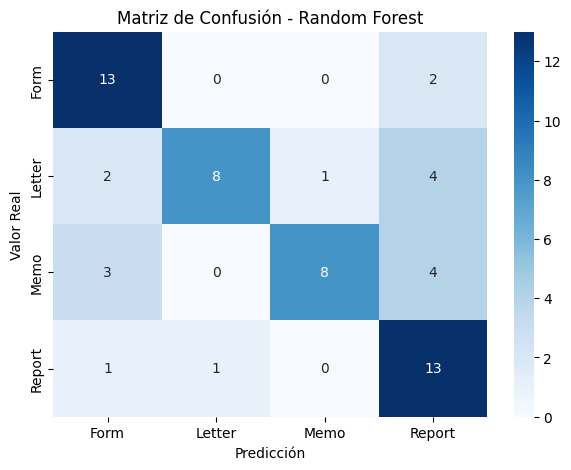

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=modelo.classes_, yticklabels=modelo.classes_)
plt.title('Matriz de Confusión - Random Forest')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

> **Análisis de la Matriz de Confusión (Random Forest):**
> * **Form y Report:** 13 aciertos de 15 cada una.
> * **Letter:** 8 aciertos; 4 documentos se predijeron como Report, 2 como Form y 1 como Memo.
> * **Memo:** 8 aciertos; 4 documentos se predijeron como Report y 3 como Form.
> * **Patrón general:** Report es la clase que más recibe predicciones erróneas (10 documentos de otras clases), lo que explica su baja precisión (0.57) pese a su alto recall (0.87).

In [ ]:
from sklearn.naive_bayes import MultinomialNB

# Entrenar Naive Bayes.
# OJO: Usamos la matriz TF-IDF original, ya que MultinomialNB no soporta los números negativos generados por SVD.
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# Predicción
y_pred_nb = nb_model.predict(X_test_tfidf)

print("--- Reporte de Clasificación (Naive Bayes) ---")
print(classification_report(y_test, y_pred_nb))

--- Reporte de Clasificación (Naive Bayes) ---
              precision    recall  f1-score   support

        Form       0.86      0.80      0.83        15
      Letter       0.87      0.87      0.87        15
        Memo       0.75      1.00      0.86        15
      Report       0.91      0.67      0.77        15

    accuracy                           0.83        60
   macro avg       0.85      0.83      0.83        60
weighted avg       0.85      0.83      0.83        60



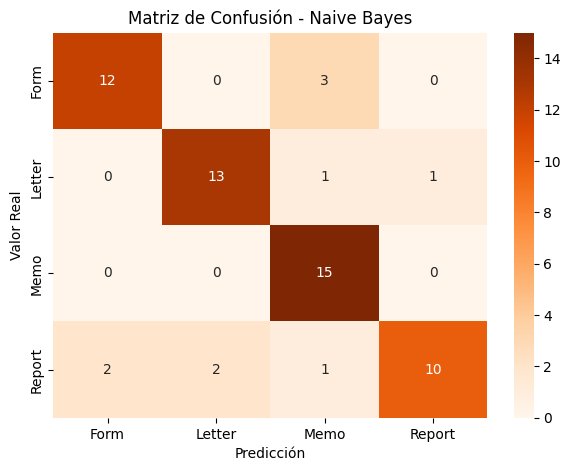

In [ ]:
cm_nb = confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Oranges',
            xticklabels=nb_model.classes_, yticklabels=nb_model.classes_)
plt.title('Matriz de Confusión - Naive Bayes')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

> **Análisis Comparativo y Conclusión:**
> * **Validación cruzada estratificada (5 folds):** Regresión logística (accuracy 0.73 ± 0.03) y Naive Bayes (0.72 ± 0.03) obtuvieron un rendimiento equivalente. El árbol de decisión (0.69 ± 0.05) quedó ligeramente por debajo, con un rango que se solapa con ambos. KNN (0.60 ± 0.04) tuvo el peor desempeño.
> * **Partición hold-out (20%, 60 documentos):** Naive Bayes alcanzó 83% y Random Forest con SVD 70%. El 83% de Naive Bayes resultó más alto que su promedio en validación cruzada (72%), por lo que depende de la partición usada.
> * **Conclusión:** No hay evidencia suficiente para declarar un único mejor modelo entre regresión logística y Naive Bayes. Se propone regresión logística como modelo base por tener la media más alta en las cuatro métricas, aunque la diferencia con Naive Bayes no es significativa. KNN se descarta por su menor desempeño.

> **Exportar dataset preprocesada**

In [ ]:
import os
from google.colab import files

# Guardar solo el nombre del archivo (la ruta de Colab no sirve fuera de esta sesión)
df_export = df_subset.copy()
df_export['archivo'] = df_export['ruta_imagen'].apply(os.path.basename)
df_export = df_export[['archivo', 'categoria', 'texto_crudo', 'texto_limpio']]

df_export.to_csv('dataset_preprocesado.csv', index=False, encoding='utf-8')
files.download('dataset_preprocesado.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>